In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [3]:
from sklearn.pipeline import Pipeline

In [10]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, balanced_accuracy_score
from sklearn.metrics import confusion_matrix, classification_report

In [12]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


In [13]:
iris = load_iris()
X = iris.data
y = iris.target

In [14]:
# Melihat nama fitur dan target
print("Nama Fitur:", iris.feature_names)
print("Nama Target (Spesies):", iris.target_names)

# Melihat bentuk data
print("Bentuk data X:", X.shape)
print("Bentuk data y:", y.shape)

# Opsional: tampilkan beberapa baris pertama data fitur
print("\nBeberapa baris pertama data fitur (X):\n", X[:5])
print("\nBeberapa baris pertama label (y):\n", y[:5])

Nama Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Nama Target (Spesies): ['setosa' 'versicolor' 'virginica']
Bentuk data X: (150, 4)
Bentuk data y: (150,)

Beberapa baris pertama data fitur (X):
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

Beberapa baris pertama label (y):
 [0 0 0 0 0]


## Eksplorasi dan persiapan data

Dataset Iris berisi empat fitur pengukuran dan tiga kelas bunga. Kita periksa bentuk data, contoh baris, statistik ringkas, dan nilai yang hilang.

In [ ]:
iris_df = pd.DataFrame(X, columns=iris.feature_names)
iris_df["species"] = pd.Categorical.from_codes(y, iris.target_names)

print(f"Jumlah baris: {len(iris_df)}")
print(f"Jumlah fitur: {len(iris.feature_names)}")
display(iris_df.head())
display(iris_df.describe())
print("\nJumlah nilai yang hilang per kolom:")
display(iris_df.isna().sum())
print("\nJumlah data per kelas:")
display(iris_df["species"].value_counts().sort_index())

## Membagi data dan memilih parameter K

Data uji disisihkan sebelum pencarian parameter. Pipeline melakukan imputasi dan standardisasi sebelum KNN; pencarian K dilakukan dengan validasi silang berstrata hanya pada data latih.

In [17]:
# Bagi data menjadi set training dan testing
# test_size=0.25 berarti 25% data digunakan untuk pengujian
# random_state=42 memastikan pembagian data yang sama setiap kali dijalankan
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Melihat bentuk data setelah pembagian
print("\nBentuk X_train:", X_train.shape)
print("Bentuk X_test:", X_test.shape)
print("Bentuk y_train:", y_train.shape)
print("Bentuk y_test:", y_test.shape)


Bentuk X_train: (112, 4)
Bentuk X_test: (38, 4)
Bentuk y_train: (112,)
Bentuk y_test: (38,)


## Evaluasi pada data uji

Data uji baru digunakan setelah model dan parameter terbaik dipilih.

In [19]:
# Pilih model supervised learning (Contoh: K-Nearest Neighbors)
# n_neighbors adalah parameter K dalam KNN
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model menggunakan data pelatihan
knn.fit(X_train, y_train)

print("\nModel KNN telah dilatih.")


Model KNN telah dilatih.


## Visualisasi

Pair plot membantu melihat pola fitur per spesies. Matriks kebingungan menunjukkan jumlah prediksi benar dan salah pada data uji.

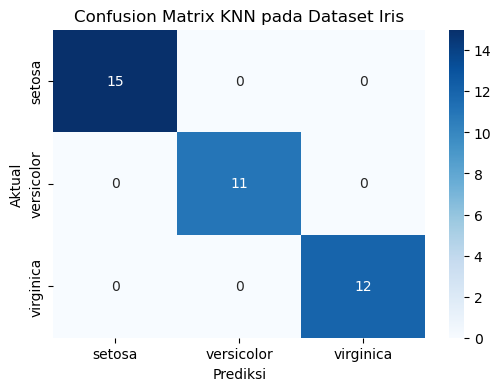

In [21]:
y_pred = knn.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=range(len(iris.target_names)))
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix KNN pada Dataset Iris")
plt.show()

## Kesimpulan

Ringkasan ini mengambil parameter terbaik dari validasi silang dan skor akhir dari data uji.

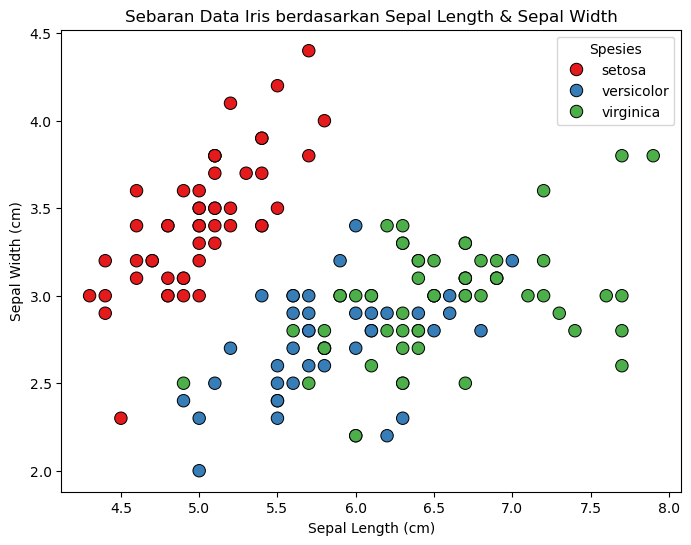

In [22]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=X[:,0], y=X[:,1], hue=iris.target_names[y], palette="Set1", s=80, edgecolor="k")

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Sebaran Data Iris berdasarkan Sepal Length & Sepal Width")
plt.legend(title="Spesies")
plt.show()

In [28]:
import pandas as pd

In [30]:
from sklearn.datasets import load_iris

iris_data = load_iris(as_frame=True)
iris = iris_data.frame

In [31]:
iris.info()
iris.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [33]:
iris = iris.drop(columns=["Id"], errors="ignore")

In [37]:
X = iris.drop(columns=["Id", "Species"], errors="ignore")
print(iris_data.target_names)

['setosa' 'versicolor' 'virginica']


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [39]:
from sklearn.tree import DecisionTreeClassifier
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [41]:
from sklearn.metrics import accuracy_score
y_pred = tree_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")

Accuracy: 1.000


In [44]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

iris_data = load_iris(as_frame=True)
iris = iris_data.frame

X = iris.drop(columns="target")
y = iris["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

data_baru = pd.DataFrame(
    [[7.9, 3.8, 5.8, 1.9]],
    columns=X.columns
)
print(iris_data.target_names[tree_model.predict(data_baru)[0]])

virginica


In [45]:
from sklearn.tree import export_graphviz

export_graphviz(tree_model, out_file="tree.dot", feature_names=X.columns, class_names=iris_data.target_names, filled=True)

In [46]:
import numpy as np
bedrooms = np.array([10, 40, 60, 80, 100])
house_prices = np.array([19000, 40000, 60000, 80000, 100000])

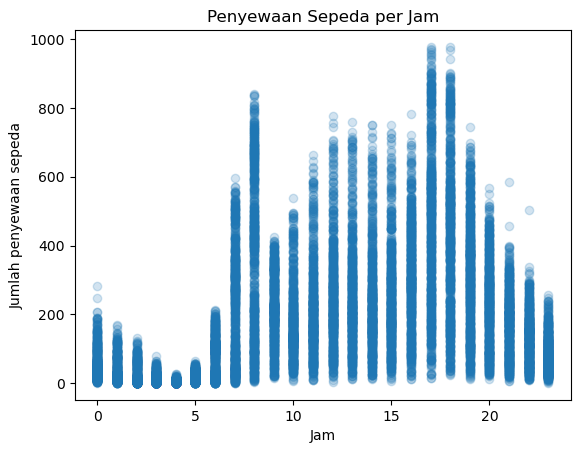

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

hour = pd.read_csv(r"bike+sharing+dataset\hour.csv")

plt.scatter(hour["hr"], hour["cnt"], alpha=0.2)
plt.xlabel("Jam")
plt.ylabel("Jumlah penyewaan sepeda")
plt.title("Penyewaan Sepeda per Jam")
plt.show()

In [68]:

from sklearn.linear_model import LinearRegression

In [72]:
import numpy as np

# Cek jumlah total elemen
print("Jumlah total elemen penjuals:", len(penjuals))

Jumlah total elemen penjuals: 2


In [75]:
print(np.array(penjuals).shape)

(2, 9)


In [76]:
penjual = np.array(penjuals).reshape(-1, 1)

In [77]:
penjual = np.array(penjuals).reshape(2, 9)

ValueError: x and y must be the same size

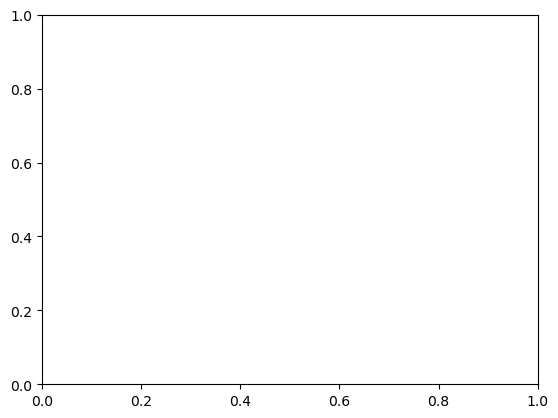

In [124]:
# Ganti angka di bawah ini dengan 18 data harga yang Anda miliki
harga = [
    15000, 20000, 25000, 30000, 35000, 40000, 45000, 50000, 55000, 
    60000, 65000, 70000, 75000, 80000, 85000, 90000, 95000, 100000
]

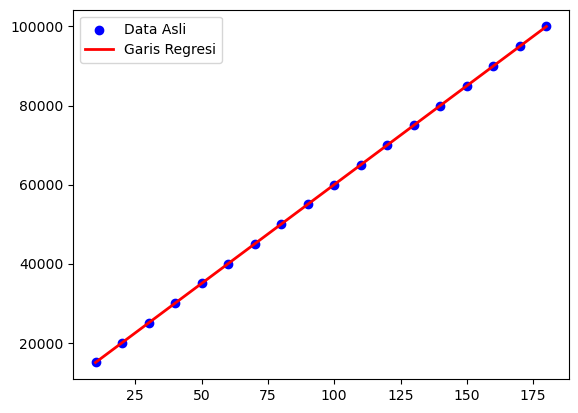

In [127]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Pastikan bentuk data penjual sudah benar (18, 1) dan harga sudah 18 data
penjual_arr = np.array(penjual).reshape(18, 1)
harga_arr = np.array(harga)

# 2. Latih model Linear Regression terlebih dahulu (JANGAN LEWATKAN INI)
linreg = LinearRegression()
linreg.fit(penjual_arr, harga_arr)

# 3. Urutkan data untuk garis regresi agar rapi
idx = penjual_arr.flatten().argsort()

# 4. Tampilkan scatter plot dan garis regresinya
plt.scatter(penjual_arr, harga_arr, color='blue', label='Data Asli')
plt.plot(penjual_arr[idx], linreg.predict(penjual_arr)[idx], color='red', linewidth=2, label='Garis Regresi')

plt.legend()
plt.show()

In [110]:
print("Jumlah data penjual:", len(penjual))
print("Jumlah data harga:", len(harga))

Jumlah data penjual: 18
Jumlah data harga: 1


In [133]:
import pandas as pd

In [136]:
import os

# Melihat daftar semua file di folder tempat Python berjalan saat ini
print(os.listdir('.'))

['.venv', 'bike+sharing+dataset', 'bike+sharing+dataset.zip', 'tree.dot', 'tugas.ipynb']


In [139]:
df = pd.read_csv("bike+sharing+dataset/hour.csv")
print(df.head())

   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  


In [140]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [141]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [146]:
data = df.drop(['instant', 'dteday'], axis=1)
data = pd.get_dummies(data)
data

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


In [145]:
print(df.columns)

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')


In [149]:
# Hapus kolom dteday dan instant dari df asli, lalu simpan ke variabel data
data = df.drop(columns=['instant', 'dteday'])

# Lakukan get_dummies (jika ada data kategori)
data = pd.get_dummies(data)

In [150]:
# y adalah target (apa yang mau diprediksi)
y = data['cnt']

# X adalah fitur (semua kolom di data KECUALI cnt)
X = data.drop(columns=['cnt'])

In [151]:
from sklearn.preprocessing import StandardScaler

In [153]:
scaler = StandardScaler()
scaler.fit(X)
scaled_data = scaler.transform(X)
scaled_data = pd.DataFrame(scaled_data, columns=X.columns)
scaled_data.head()

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered
0,-1.356634,-1.005134,-1.610438,-1.670004,-0.172112,1.493891,-1.4669,-0.665193,-1.334648,-1.093281,0.947372,-1.553889,-0.662755,-0.930189
1,-1.356634,-1.005134,-1.610438,-1.525374,-0.172112,1.493891,-1.4669,-0.665193,-1.438516,-1.181732,0.895539,-1.553889,-0.561343,-0.804655
2,-1.356634,-1.005134,-1.610438,-1.380744,-0.172112,1.493891,-1.4669,-0.665193,-1.438516,-1.181732,0.895539,-1.553889,-0.622190,-0.837690
3,-1.356634,-1.005134,-1.610438,-1.236115,-0.172112,1.493891,-1.4669,-0.665193,-1.334648,-1.093281,0.636370,-1.553889,-0.662755,-0.950010
4,-1.356634,-1.005134,-1.610438,-1.091485,-0.172112,1.493891,-1.4669,-0.665193,-1.334648,-1.093281,0.636370,-1.553889,-0.723603,-1.009474


In [154]:
from sklearn.linear_model import LinearRegression
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [157]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train, y_train)

c:\Users\Ilham\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [158]:
model.score(X_test, y_test)

0.027905638665132335